# Assignment 3: Time-Series Data — Jena climate forecasting

**Analysis task.** How accurately can we predict air temperature 24 hours ahead from the preceding five days of weather? We compare seasonal persistence with GRU and LSTM models (32 and 64 units) and an optional Conv1D–GRU model.

**Protocol** Use the actual Jena climate 2009–2016 CSV. Aggregate ten-minute records into hourly means, replace `-9999` missing markers, and fill gaps using earlier observations only. Split in time order (70% train, 15% validation, 15% test), fit scaling on training data only, and keep every input window and target within its own split. Choose by validation MAE in °C, then evaluate the selected model once on the test split. A six-hour window stride keeps the experiment practical while covering the full date range.

**Reproducibility** Fixed random seed 42; Kaggle dataset `stytch16/jena-climate-2009-2016`. Run all cells from top to bottom.

In [12]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
paths = glob.glob('/kaggle/input/**/jena_climate_2009_2016.csv', recursive=True)
assert len(paths) == 1, f'Expected one Jena CSV, found: {paths}'
df = pd.read_csv(paths[0])
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')
print('Dataset:', paths[0], '| shape:', df.shape)
print('Dates:', df['Date Time'].min(), 'to', df['Date Time'].max())
display(df.head())

Dataset: /kaggle/input/datasets/stytch16/jena-climate-2009-2016/jena_climate_2009_2016.csv | shape: (420551, 15)
Dates: 2009-01-01 00:10:00 to 2017-01-01 00:00:00


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,2009-01-01 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,2009-01-01 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,2009-01-01 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,2009-01-01 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,2009-01-01 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


Original rows: 420551 | hourly rows: 70129 | variables: 14
Missing-value markers: 38 | empty hourly temperature bins: 88
Missing bins/values filled using earlier observations only.


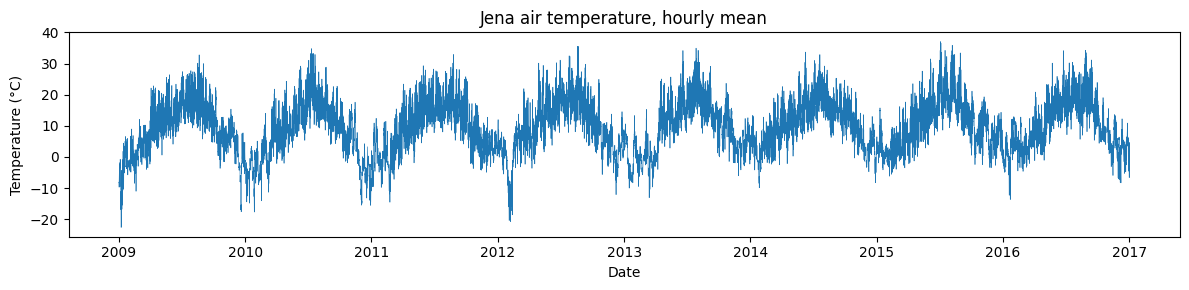

,split,rows,from,through
0,train,49090,2009-01-01 00:00:00,2014-08-08 09:00:00
1,validation,10519,2014-08-08 10:00:00,2015-10-20 16:00:00
2,test,10520,2015-10-20 17:00:00,2017-01-01 00:00:00


Training-only temperature mean/std: 9.11 8.645


In [13]:
target_col = 'T (degC)'
features = [c for c in df.columns if c != 'Date Time']
sentinel_count = int((df[features] == -9999).sum().sum())
raw = df.sort_values('Date Time').set_index('Date Time')[features].replace(-9999, np.nan)
hourly_raw = raw.resample('1h').mean()
missing_bins = int(hourly_raw[target_col].isna().sum())
hourly = hourly_raw.ffill().reset_index()
assert not hourly[features].isna().any().any()
assert hourly['Date Time'].diff().dropna().eq(pd.Timedelta(hours=1)).all()
print('Original rows:', len(df), '| hourly rows:', len(hourly), '| variables:', len(features))
print('Missing-value markers:', sentinel_count, '| empty hourly temperature bins:', missing_bins)
print('Missing bins/values filled using earlier observations only.')
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(hourly['Date Time'], hourly[target_col], linewidth=.45)
ax.set(title='Jena air temperature, hourly mean', xlabel='Date', ylabel='Temperature (°C)')
fig.tight_layout(); plt.show()

n = len(hourly)
cut1, cut2 = int(n * .70), int(n * .85)
segments = {'train': hourly.iloc[:cut1], 'validation': hourly.iloc[cut1:cut2], 'test': hourly.iloc[cut2:]}
summary = pd.DataFrame([{'split': k, 'rows': len(v), 'from': v['Date Time'].iloc[0], 'through': v['Date Time'].iloc[-1]} for k, v in segments.items()])
display(summary)
mu = segments['train'][features].mean().to_numpy(dtype='float32')
sigma = segments['train'][features].std().replace(0, 1).to_numpy(dtype='float32')
print('Training-only temperature mean/std:', round(float(mu[features.index(target_col)]), 3), round(float(sigma[features.index(target_col)]), 3))

## Forecast windows and baseline

Each example contains 120 consecutive hourly observations (five days). The target is temperature 24 hourly steps after the final observed hour. Windows start every six hours; no example crosses a train, validation, or test boundary. The **seasonal persistence** baseline predicts that tomorrow’s temperature equals the temperature at the last observed hour, exactly one day earlier. We measure mean absolute error (MAE) in °C.

In [14]:
HISTORY, HORIZON, STRIDE = 120, 24, 6
temp_idx = features.index(target_col)

def make_windows(part):
    values = part[features].to_numpy(dtype='float32')
    scaled = (values - mu) / sigma
    starts = np.arange(0, len(part) - HISTORY - HORIZON + 1, STRIDE)
    target_idx = starts + HISTORY - 1 + HORIZON
    X = np.stack([scaled[s:s + HISTORY] for s in starts]).astype('float32')
    y = scaled[target_idx, temp_idx].astype('float32')
    actual = values[target_idx, temp_idx]
    last_temp = values[starts + HISTORY - 1, temp_idx]
    dates = part['Date Time'].iloc[target_idx].reset_index(drop=True)
    assert ((dates.to_numpy() - part['Date Time'].iloc[starts + HISTORY - 1].to_numpy()) == np.timedelta64(24, 'h')).all()
    return X, y, actual, last_temp, dates

X_train, y_train, _, _, train_dates = make_windows(segments['train'])
X_val, y_val, val_actual, val_last, val_dates = make_windows(segments['validation'])
baseline_val_mae = float(np.mean(np.abs(val_actual - val_last)))
print('Train windows:', X_train.shape, '| validation windows:', X_val.shape)
print('First/last training target:', train_dates.iloc[0], train_dates.iloc[-1])
print('First/last validation target:', val_dates.iloc[0], val_dates.iloc[-1])
print(f'Seasonal persistence validation MAE: {baseline_val_mae:.3f} °C')

Train windows: (8158, 120, 14) | validation windows: (1730, 120, 14)
First/last training target: 2009-01-06 23:00:00 2014-08-08 05:00:00
First/last validation target: 2014-08-14 09:00:00 2015-10-20 15:00:00
Seasonal persistence validation MAE: 2.586 °C


## Recurrent and convolutional experiments

All five neural models use the same normalized inputs, 24-hour target, training windows, validation windows, optimizer, batch size, maximum epochs, and early stopping rule. Only the architecture changes: GRU with 32 or 64 units, LSTM with 32 or 64 units, or a causal Conv1D layer followed by a 32-unit GRU. Early stopping monitors validation loss and restores the best epoch. Validation predictions are converted back to °C before scoring.

In [15]:
tf.keras.backend.clear_session()

def build_model(kind, units):
    inputs = tf.keras.Input(shape=(HISTORY, len(features)))
    if kind == 'Conv1D+GRU':
        x = tf.keras.layers.Conv1D(32, 5, padding='causal', activation='relu')(inputs)
        x = tf.keras.layers.GRU(units)(x)
    elif kind == 'GRU':
        x = tf.keras.layers.GRU(units)(inputs)
    else:
        x = tf.keras.layers.LSTM(units)(inputs)
    outputs = tf.keras.layers.Dense(1)(x)
    model = tf.keras.Model(inputs, outputs, name='forecast_' + kind.replace('+', '_') + '_' + str(units))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model

specs = [('GRU', 32), ('GRU', 64), ('LSTM', 32), ('LSTM', 64), ('Conv1D+GRU', 32)]
models, histories = {}, {}
training_rows = [{'model': 'Seasonal persistence', 'architecture': 'Baseline', 'units': 0, 'epochs': 0, 'validation_MAE_C': baseline_val_mae}]
for i, (kind, units) in enumerate(specs):
    tf.keras.utils.set_random_seed(SEED + i)
    name = f'{kind} {units}'
    model = build_model(kind, units)
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, min_delta=1e-4, restore_best_weights=True), tf.keras.callbacks.TerminateOnNaN()]
    print('Training', name, flush=True)
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=8, batch_size=256, callbacks=callbacks, verbose=0)
    pred_c = model.predict(X_val, batch_size=512, verbose=0).ravel() * sigma[temp_idx] + mu[temp_idx]
    val_mae_c = float(np.mean(np.abs(val_actual - pred_c)))
    models[name], histories[name] = model, history.history
    training_rows.append({'model': name, 'architecture': kind, 'units': units, 'epochs': len(history.history['loss']), 'validation_MAE_C': val_mae_c})
    print(f'{name}: {val_mae_c:.3f} °C validation MAE after {len(history.history["loss"])} epochs', flush=True)
comparison = pd.DataFrame(training_rows).sort_values('validation_MAE_C').reset_index(drop=True)
display(comparison.round(3))

Training GRU 32
GRU 32: 2.423 °C validation MAE after 8 epochs
Training GRU 64
GRU 64: 2.469 °C validation MAE after 8 epochs
Training LSTM 32
LSTM 32: 2.492 °C validation MAE after 8 epochs
Training LSTM 64
LSTM 64: 2.416 °C validation MAE after 8 epochs
Training Conv1D+GRU 32
Conv1D+GRU 32: 2.463 °C validation MAE after 8 epochs


,model,architecture,units,epochs,validation_MAE_C
0,LSTM 64,LSTM,64,8,2.416
1,GRU 32,GRU,32,8,2.423
2,Conv1D+GRU 32,Conv1D+GRU,32,8,2.463
3,GRU 64,GRU,64,8,2.469
4,LSTM 32,LSTM,32,8,2.492
5,Seasonal persistence,Baseline,0,0,2.586


## Validation comparison and selection

The table above contains every measured validation MAE in °C. The bar chart below makes the ranking visible, and the learning curves show how training and validation errors changed over the epochs. We select the smallest validation MAE, including the baseline as an eligible candidate. Because the GRU 32 and LSTM 64 values are close, a single fixed-seed run does not establish that one architecture is consistently superior.

Selected on validation only: LSTM 64, MAE 2.416 °C
Change from seasonal persistence: 6.6% lower MAE


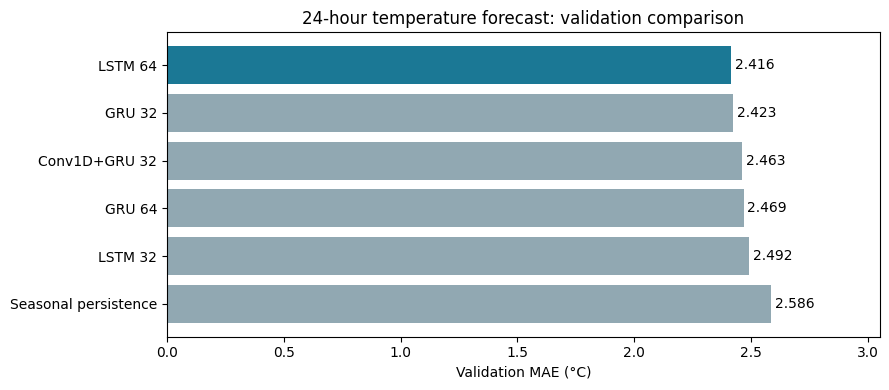

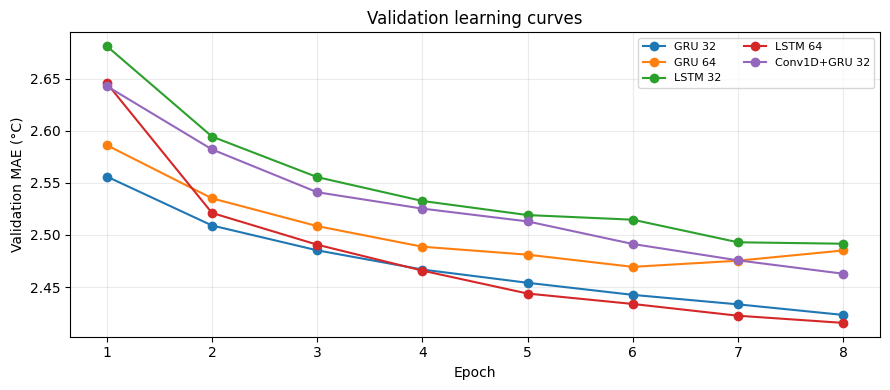

In [16]:
best_name = comparison.iloc[0]['model']
best_val_mae = float(comparison.iloc[0]['validation_MAE_C'])
print(f'Selected on validation only: {best_name}, MAE {best_val_mae:.3f} °C')
print(f'Change from seasonal persistence: {(baseline_val_mae - best_val_mae) / baseline_val_mae * 100:.1f}% lower MAE')

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(comparison['model'], comparison['validation_MAE_C'], color=['#1b7895'] + ['#91a8b2'] * (len(comparison)-1))
ax.invert_yaxis()
ax.set(xlabel='Validation MAE (°C)', title='24-hour temperature forecast: validation comparison')
for i, v in enumerate(comparison['validation_MAE_C']): ax.text(v + .015, i, f'{v:.3f}', va='center')
ax.set_xlim(0, comparison['validation_MAE_C'].max() * 1.18)
fig.tight_layout(); fig.savefig('/kaggle/working/validation_comparison.png', dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for name, h in histories.items():
    ax.plot(np.arange(1, len(h['val_loss']) + 1), np.array(h['val_loss']) * sigma[temp_idx], marker='o', label=name)
ax.set(xlabel='Epoch', ylabel='Validation MAE (°C)', title='Validation learning curves')
ax.legend(ncol=2, fontsize=8); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig('/kaggle/working/learning_curves.png', dpi=160); plt.show()
comparison.to_csv('/kaggle/working/validation_results.csv', index=False)
if best_name in models: models[best_name].save('/kaggle/working/best_temperature_model.keras')

,selected_model,validation_MAE_C,test_MAE_C,test_windows
0,LSTM 64,2.416,2.317,1730


First/last test target: 2015-10-26 16:00:00 2016-12-31 22:00:00


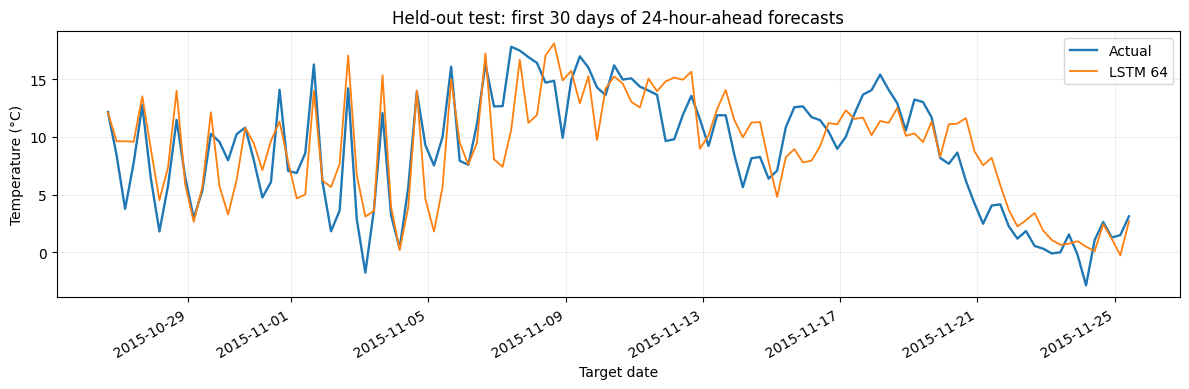

In [17]:
X_test, y_test, test_actual, test_last, test_dates = make_windows(segments['test'])
if best_name == 'Seasonal persistence':
    test_pred = test_last.copy()
else:
    test_pred = models[best_name].predict(X_test, batch_size=512, verbose=0).ravel() * sigma[temp_idx] + mu[temp_idx]
test_mae = float(np.mean(np.abs(test_actual - test_pred)))
test_summary = pd.DataFrame([{'selected_model': best_name, 'validation_MAE_C': best_val_mae, 'test_MAE_C': test_mae, 'test_windows': len(test_actual)}])
display(test_summary.round(3))
print('First/last test target:', test_dates.iloc[0], test_dates.iloc[-1])

predictions = pd.DataFrame({'target_time': test_dates, 'actual_temperature_C': test_actual, 'predicted_temperature_C': test_pred, 'absolute_error_C': np.abs(test_actual - test_pred)})
predictions.to_csv('/kaggle/working/test_predictions.csv', index=False)
test_summary.to_csv('/kaggle/working/final_test_metrics.csv', index=False)
fig, ax = plt.subplots(figsize=(12, 4))
show = slice(0, 120)
ax.plot(test_dates.iloc[show], test_actual[show], label='Actual', linewidth=1.7)
ax.plot(test_dates.iloc[show], test_pred[show], label=best_name, linewidth=1.3)
ax.set(title='Held-out test: first 30 days of 24-hour-ahead forecasts', xlabel='Target date', ylabel='Temperature (°C)')
ax.legend(); ax.grid(alpha=.2)
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig('/kaggle/working/test_forecast_example.png', dpi=160); plt.show()

In [18]:
from pathlib import Path
import base64
out = Path('/kaggle/working')
def inline_png(name):
    encoded = base64.b64encode((out / name).read_bytes()).decode('ascii')
    return '<img alt="' + name + '" src="data:image/png;base64,' + encoded + '">'

style = 'body{font:16px/1.55 system-ui,sans-serif;max-width:920px;margin:40px auto;padding:0 20px;color:#23313b}h1,h2{color:#173e52}table{border-collapse:collapse;width:100%;margin:16px 0}th,td{border:1px solid #cbd5dc;padding:7px;text-align:left}th{background:#edf4f7}img{max-width:100%;height:auto;margin:12px 0 24px}.note{background:#edf4f7;padding:14px;border-left:4px solid #1b7895}'
report = '<!doctype html><html lang="en"><meta charset="utf-8"><title>Assignment 3 — Jena climate forecast</title><style>' + style + '</style><main>'
report += '<h1>Assignment 3: Time-Series Data</h1><p>Jena climate 2009–2016; 24-hour-ahead temperature forecasting from five days of hourly weather history.</p>'
report += '<p>Source: <a href="https://www.kaggle.com/datasets/stytch16/jena-climate-2009-2016">Jena climate CSV on Kaggle</a>. The CSV has 420,551 raw rows and 14 weather measurements.</p>'
report += '<h2>Method</h2><p>Ten-minute observations were aggregated to hourly means. The 38 missing-value markers and 88 empty hourly temperature bins were filled from prior observations. Chronological 70/15/15 train/validation/test split; scaling fitted on training rows only. Each example uses 120 hours of history and predicts temperature 24 hours after the final input, with a six-hour window stride. No window crosses a split boundary.</p>'
report += summary.to_html(index=False)
report += '<h2>Validation comparison</h2><p>Seasonal persistence and five neural architectures were compared by MAE in °C. Models used Adam, MAE loss, up to eight epochs, batch size 256, and early stopping.</p>'
report += comparison.round(3).to_html(index=False)
report += inline_png('validation_comparison.png') + inline_png('learning_curves.png')
report += '<h2>Final held-out test</h2>' + test_summary.round(3).to_html(index=False)
report += inline_png('test_forecast_example.png')
report += f'<h2>Conclusions</h2><p>{best_name} had the lowest validation MAE ({best_val_mae:.3f} °C), {(baseline_val_mae-best_val_mae)/baseline_val_mae*100:.1f}% below seasonal persistence ({baseline_val_mae:.3f} °C). Its single final test MAE was {test_mae:.3f} °C on {len(test_actual):,} forecasts.</p>'
report += '<p>The GRU 32 and LSTM 64 validation errors were close; one seeded run cannot establish a general winner. A larger GRU did not improve on GRU 32, and the optional Conv1D–GRU did not lead this run. Six-hour window spacing, limited epochs, and past-only filling of missing observations constrain the result.</p>'
report += '<p class="note">The test split was used only after selection on validation. Full reproducible code and outputs are in the Kaggle notebook; CSV files and PNG plots are saved beside this report.</p></main></html>'
(out / 'assignment3_report.html').write_text(report, encoding='utf-8')
print('Saved standalone HTML report:', out / 'assignment3_report.html')
print('Output artifacts:', sorted(p.name for p in out.iterdir() if p.is_file()))

Saved standalone HTML report: /kaggle/working/assignment3_report.html
Output artifacts: ['assignment3_report.html', 'best_temperature_model.keras', 'final_test_metrics.csv', 'learning_curves.png', 'test_forecast_example.png', 'test_predictions.csv', 'validation_comparison.png', 'validation_results.csv']


In [19]:

# Test GRU 32 on the held-out test dataset

gru32_model = models['GRU 32']

# Predict temperatures and convert back to Celsius
gru32_pred = gru32_model.predict(
    X_test, batch_size=512, verbose=0
).ravel() * sigma[temp_idx] + mu[temp_idx]

# Calculate test MAE
gru32_test_mae = float(
    np.mean(np.abs(test_actual - gru32_pred))
)

print(f"GRU 32 Test MAE: {gru32_test_mae:.3f} °C")
print(f"LSTM 64 Test MAE: {test_mae:.3f} °C")

# Compare both models
test_comparison = pd.DataFrame({
    'Model': ['LSTM 64', 'GRU 32'],
    'Validation MAE (°C)': [
        best_val_mae,
        float(comparison.loc[
            comparison['model'] == 'GRU 32',
            'validation_MAE_C'
        ].iloc[0])
    ],
    'Test MAE (°C)': [
        test_mae,
        gru32_test_mae
    ]
})

display(test_comparison.round(3))

# Save comparison results
test_comparison.to_csv(
    '/kaggle/working/test_model_comparison.csv',
    index=False
)


GRU 32 Test MAE: 2.339 °C
LSTM 64 Test MAE: 2.317 °C


,Model,Validation MAE (°C),Test MAE (°C)
0,LSTM 64,2.416,2.317
1,GRU 32,2.423,2.339
